# Clustering Track

## 1. Setup and configuration

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="colorblind")
PALETTE = "tab10"
os.makedirs("../figures", exist_ok=True)
os.makedirs("../models", exist_ok=True)

### Dataset configuration

In [2]:
DATA_PATH = None          # e.g. "../data/your_dataset.csv"
LABEL_COL = None          # e.g. "target"; None if the dataset has no labels
DROP_COLS = []            # ID-like columns that carry no information (e.g. ["id"])
K_RANGE   = range(2, 11)  # candidate k values for K-Means

## 2. Data loading and audit

In [3]:
def load_data(path, label_col):
    if path is None:
        from sklearn.datasets import load_wine
        raw = load_wine(as_frame=True)
        df = raw.frame.copy()
        return df, "target"
    return pd.read_csv(path), label_col

df, LABEL_COL = load_data(DATA_PATH, LABEL_COL)
df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])
print("Shape:", df.shape)
df.head()

Shape: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
print("Duplicate rows:", df.duplicated().sum())
audit

Duplicate rows: 0


,dtype,missing,missing_%,n_unique
alcohol,float64,0,0.0,126
malic_acid,float64,0,0.0,133
ash,float64,0,0.0,79
alcalinity_of_ash,float64,0,0.0,63
magnesium,float64,0,0.0,53
total_phenols,float64,0,0.0,97
flavanoids,float64,0,0.0,132
nonflavanoid_phenols,float64,0,0.0,39
proanthocyanins,float64,0,0.0,101
color_intensity,float64,0,0.0,132


In [5]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


## 3. Exploratory data analysis

In [6]:
# Separate features from the label. The label is NOT used for fitting.
y_true = df[LABEL_COL].copy() if LABEL_COL else None
X_raw = df.drop(columns=[LABEL_COL]) if LABEL_COL else df.copy()

num_cols = X_raw.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_raw.select_dtypes(exclude=np.number).columns.tolist()
print(f"{len(num_cols)} numeric features, {len(cat_cols)} categorical features")

13 numeric features, 0 categorical features


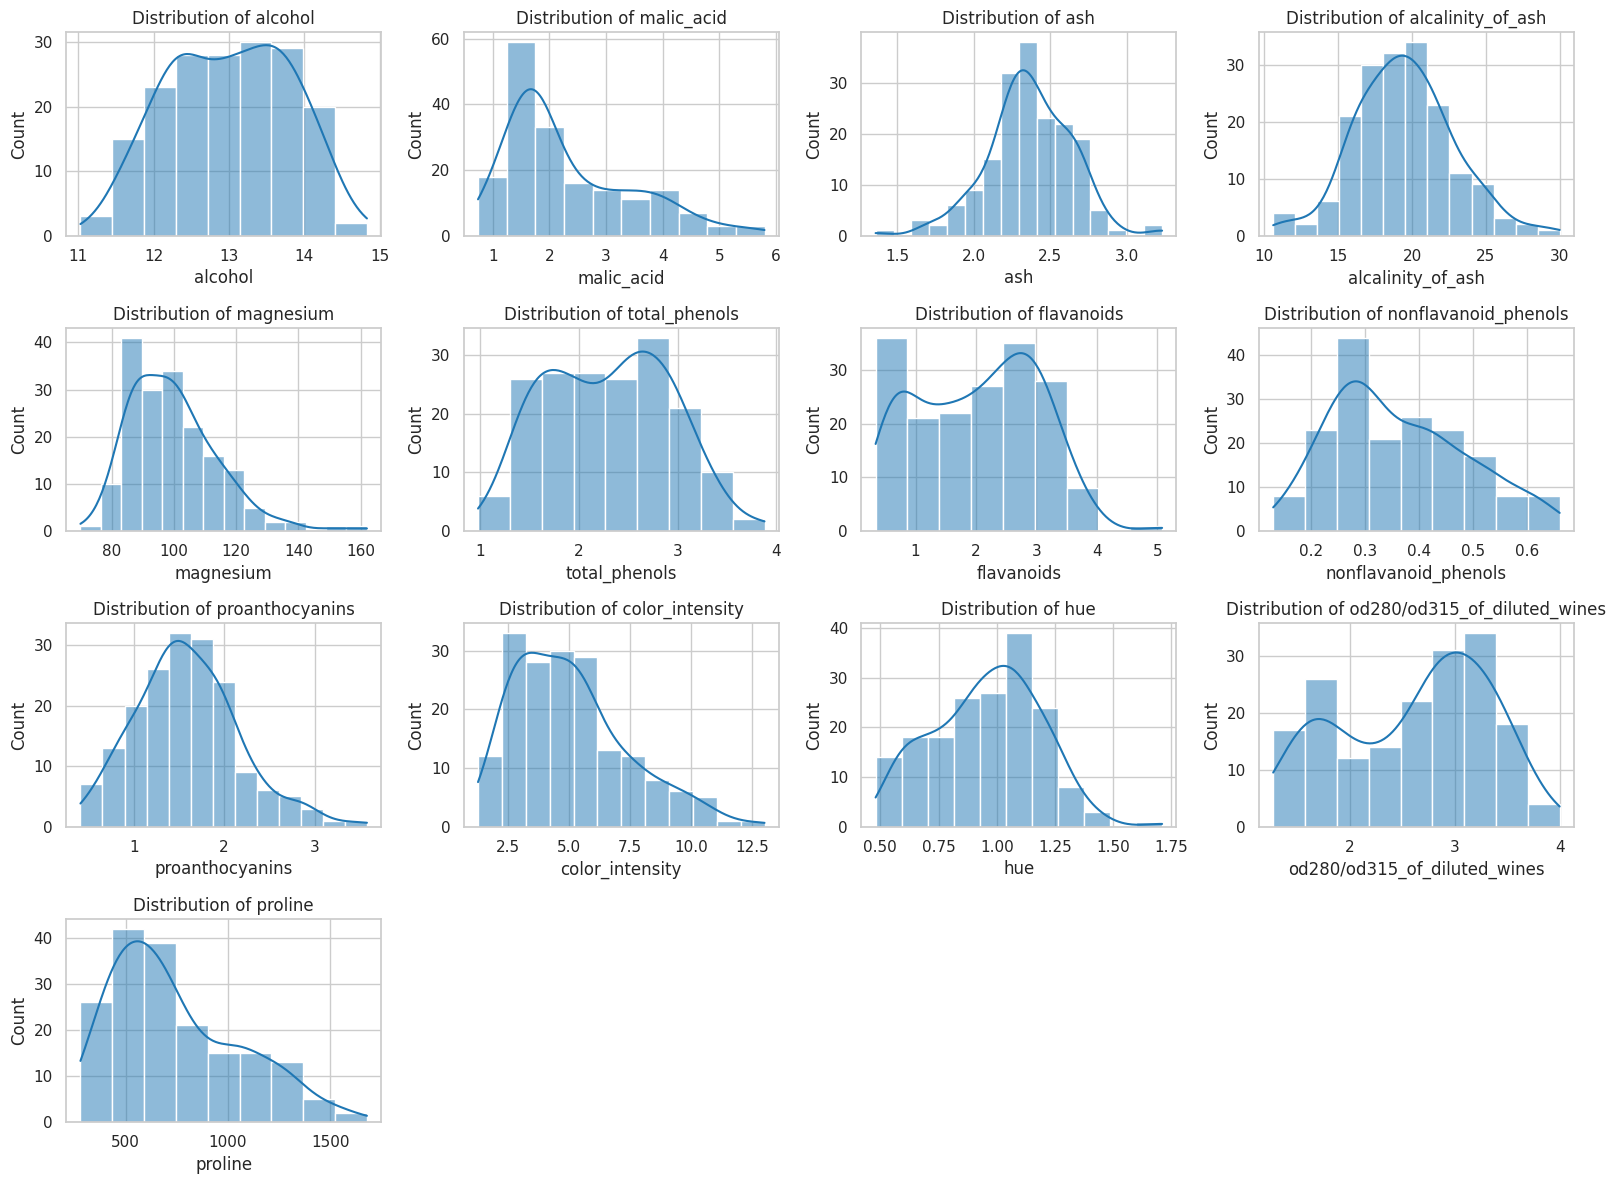

In [7]:
# Distribution of every numeric feature
n = len(num_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(X_raw[col], kde=True, ax=ax, color=sns.color_palette(PALETTE)[0])
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col); ax.set_ylabel("Count")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("../figures/clu_feature_distributions.png", bbox_inches="tight")
plt.show()

**✍️ Your observation (distributions):** _skew, multimodality (hint of natural groups?), scale differences between features..._

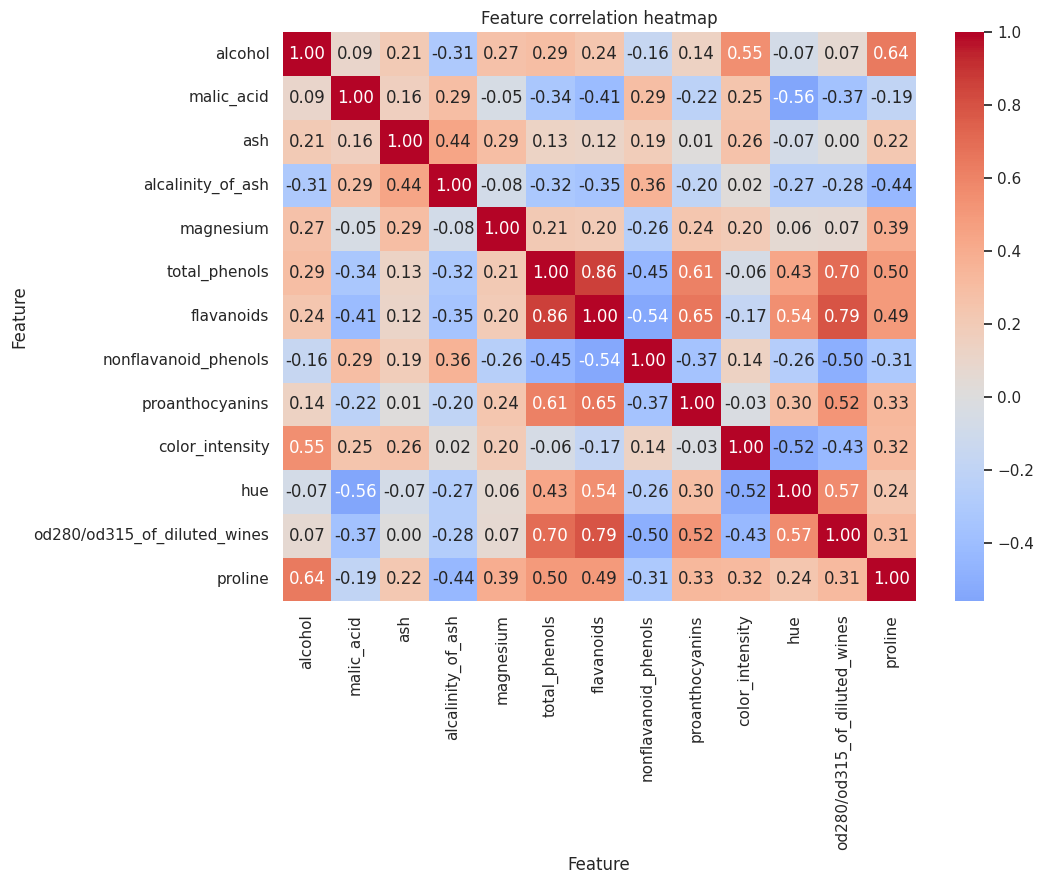

In [8]:
plt.figure(figsize=(11, 9))
sns.heatmap(X_raw[num_cols].corr(), cmap="coolwarm", center=0, annot=len(num_cols) <= 15, fmt=".2f")
plt.title("Feature correlation heatmap")
plt.xlabel("Feature"); plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("../figures/clu_correlation_heatmap.png", bbox_inches="tight")
plt.show()

In [9]:
# Outlier check (IQR rule) — distance-based clustering is sensitive to outliers
Q1, Q3 = X_raw[num_cols].quantile(0.25), X_raw[num_cols].quantile(0.75)
IQR = Q3 - Q1
outlier_counts = ((X_raw[num_cols] < Q1 - 1.5 * IQR) | (X_raw[num_cols] > Q3 + 1.5 * IQR)).sum()
outlier_counts.sort_values(ascending=False).to_frame("n_outliers_IQR")

,n_outliers_IQR
magnesium,4
alcalinity_of_ash,4
color_intensity,4
malic_acid,3
ash,3
proanthocyanins,2
hue,1
alcohol,0
total_phenols,0
nonflavanoid_phenols,0


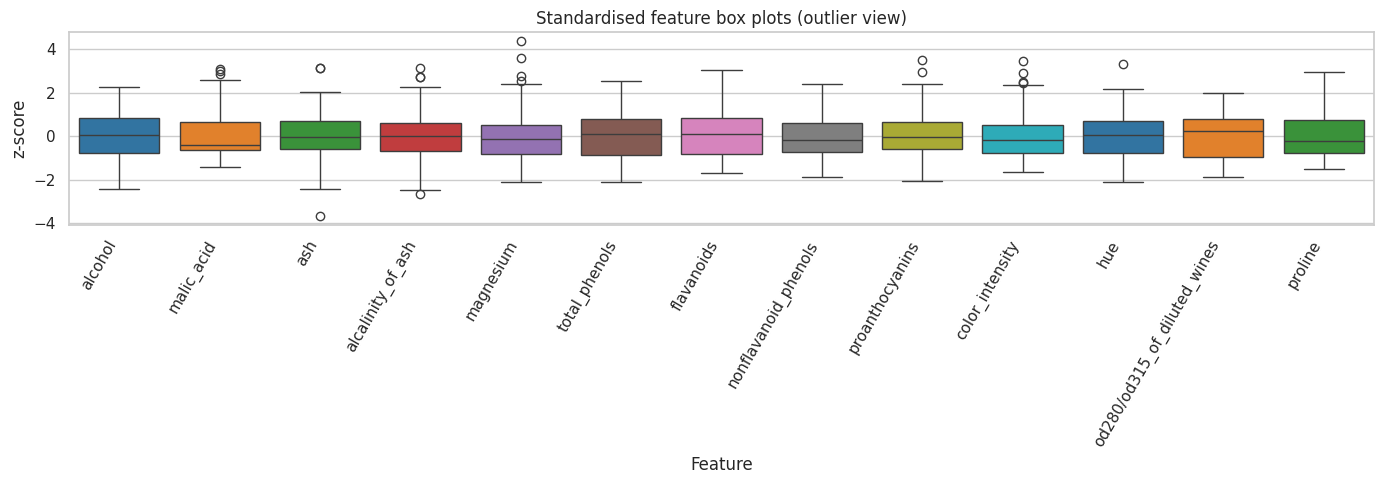

In [10]:
plt.figure(figsize=(14, 5))
sns.boxplot(data=(X_raw[num_cols] - X_raw[num_cols].mean()) / X_raw[num_cols].std(), palette=PALETTE)
plt.title("Standardised feature box plots (outlier view)")
plt.xlabel("Feature"); plt.ylabel("z-score")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig("../figures/clu_boxplots.png", bbox_inches="tight")
plt.show()

## 4. Preprocessing

- **Duplicates** removed.
- **Missing values:** median imputation for numeric features (robust to skew/outliers), most-frequent for categoricals.
- **Outliers:** capped at the 1st/99th percentile (winsorising) so extreme points do not pull centroids, without deleting rows.
- **Encoding:** one-hot for categoricals.
- **Scaling:** `StandardScaler` — essential because K-Means and Ward linkage use Euclidean distance, so a large-range feature would otherwise dominate.


In [11]:
X = X_raw.drop_duplicates().copy()
if y_true is not None:
    y_true = y_true.loc[X.index]
print("Rows after removing duplicates:", len(X))

# Winsorise numeric features at the 1st/99th percentile
lo, hi = X[num_cols].quantile(0.01), X[num_cols].quantile(0.99)
X[num_cols] = X[num_cols].clip(lo, hi, axis=1)

transformers = [("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                                  ("scale", StandardScaler())]), num_cols)]
if cat_cols:
    transformers.append(("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols))
preprocessor = ColumnTransformer(transformers)

X_scaled = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()
print("Preprocessed matrix:", X_scaled.shape)

Rows after removing duplicates: 178
Preprocessed matrix: (178, 13)


In [12]:
def evaluate_clustering(X, labels, name):
    """Return the three mandatory internal metrics for one clustering result."""
    return {
        "Algorithm": name,
        "n_clusters": len(np.unique(labels)),
        "Silhouette": silhouette_score(X, labels),
        "Davies-Bouldin": davies_bouldin_score(X, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X, labels),
    }

results = []

## 5. K-Means clustering
### 5.1 Elbow curve (inertia vs k) and silhouette vs k

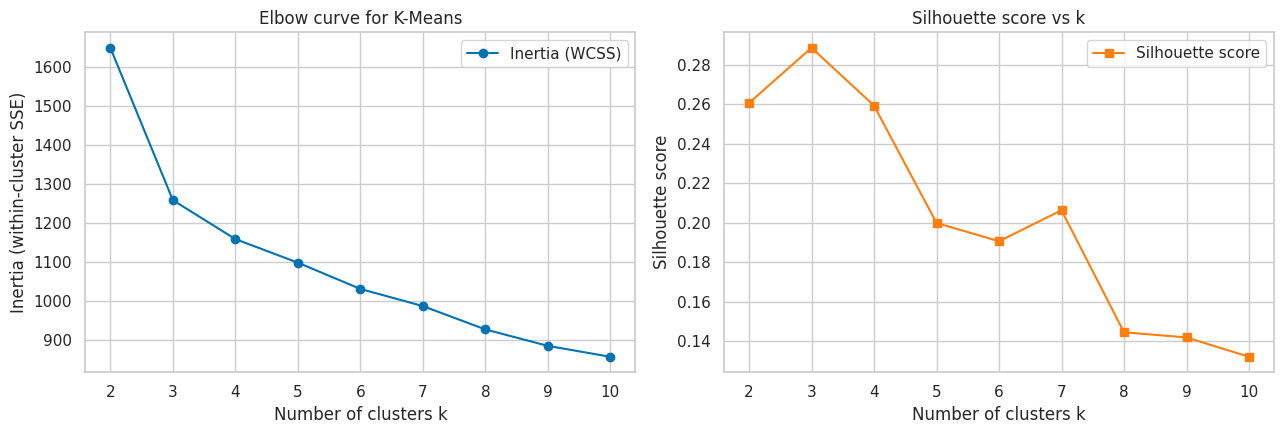

,k,inertia,silhouette
0,2,1649.0808,0.2606
1,3,1258.8814,0.2885
2,4,1159.2771,0.2593
3,5,1098.9490,0.2000
4,6,1031.6826,0.1907
5,7,987.7607,0.2063
6,8,928.0440,0.1446
7,9,885.8868,0.1420
8,10,857.9449,0.1322


In [13]:
k_stats = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    k_stats.append({"k": k, "inertia": km.inertia_,
                    "silhouette": silhouette_score(X_scaled, km.labels_)})
k_stats = pd.DataFrame(k_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_stats["k"], k_stats["inertia"], "o-", label="Inertia (WCSS)")
axes[0].set_title("Elbow curve for K-Means")
axes[0].set_xlabel("Number of clusters k"); axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].legend()
axes[1].plot(k_stats["k"], k_stats["silhouette"], "s-", color="tab:orange", label="Silhouette score")
axes[1].set_title("Silhouette score vs k")
axes[1].set_xlabel("Number of clusters k"); axes[1].set_ylabel("Silhouette score")
axes[1].legend()
plt.tight_layout()
plt.savefig("../figures/clu_kmeans_elbow.png", bbox_inches="tight")
plt.show()
k_stats.round(4)

In [14]:
# Default choice: k with the best silhouette. Override after reading the elbow if you disagree.
K_OVERRIDE = None
best_k = K_OVERRIDE or int(k_stats.loc[k_stats["silhouette"].idxmax(), "k"])
print("Chosen k for K-Means:", best_k)

Chosen k for K-Means: 3


### 5.2 Final K-Means model

In [15]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_scaled)
results.append(evaluate_clustering(X_scaled, kmeans_labels, f"K-Means (k={best_k})"))
print("Cluster sizes:", np.bincount(kmeans_labels))

Cluster sizes: [66 51 61]


## 6. Agglomerative hierarchical clustering
### 6.1 Dendrograms — comparing linkage strategies

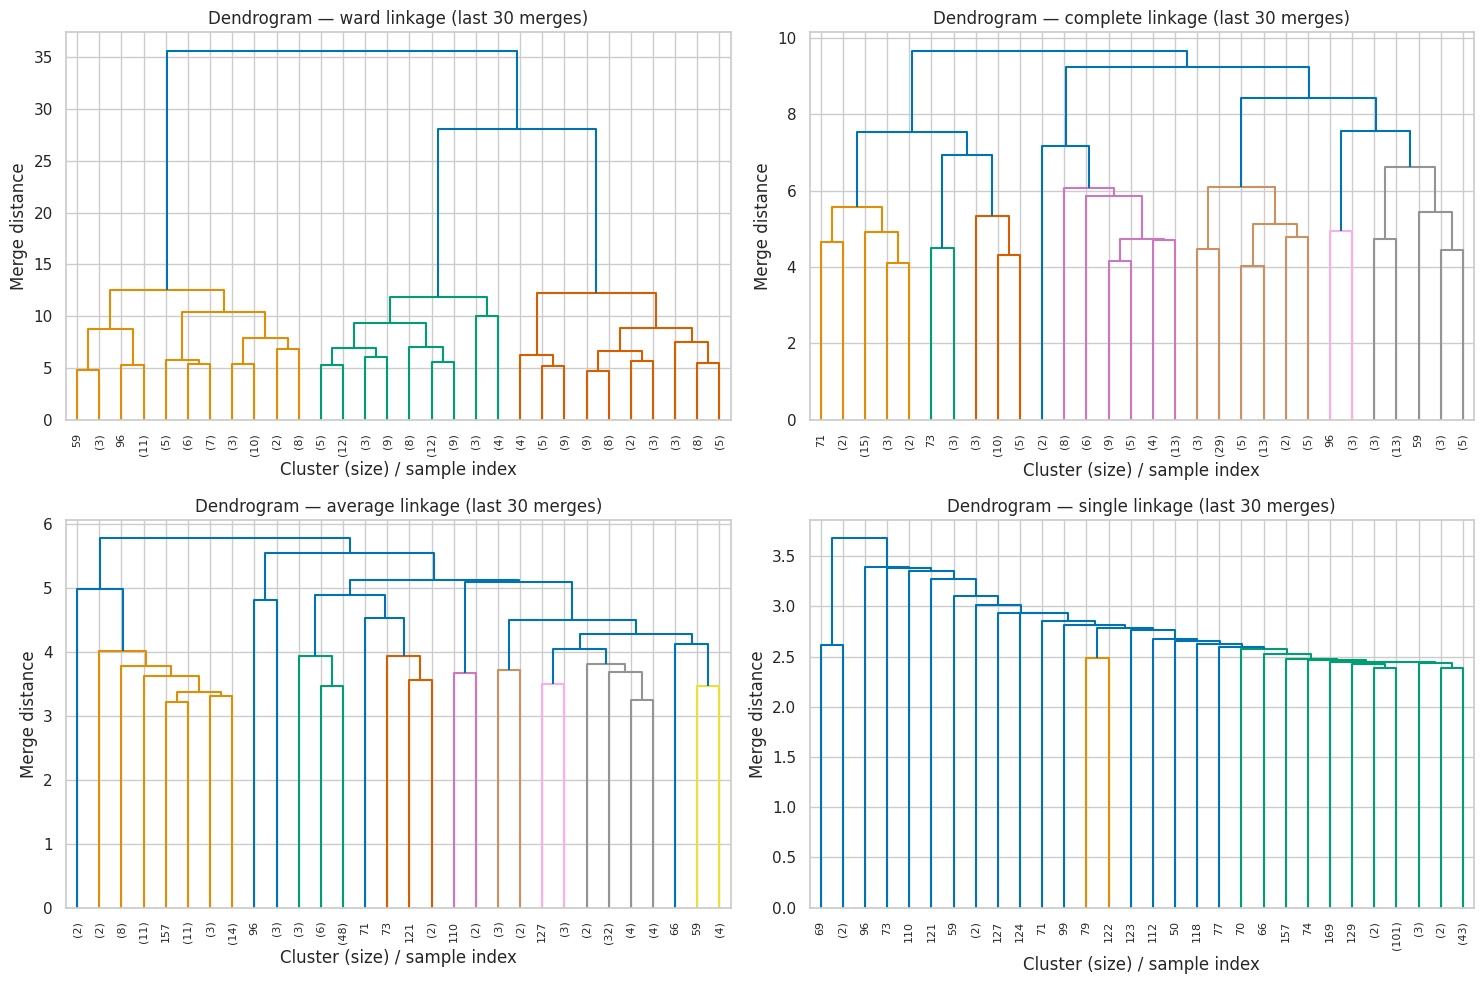

In [16]:
LINKAGES = ["ward", "complete", "average", "single"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, method in zip(axes.ravel(), LINKAGES):
    Z = linkage(X_scaled, method=method)
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, color_threshold=None,
               leaf_rotation=90, leaf_font_size=8)
    ax.set_title(f"Dendrogram — {method} linkage (last 30 merges)")
    ax.set_xlabel("Cluster (size) / sample index"); ax.set_ylabel("Merge distance")
plt.tight_layout()
plt.savefig("../figures/clu_dendrograms.png", bbox_inches="tight")
plt.show()

### 6.2 Linkage comparison at the same number of clusters

In [17]:
link_rows, link_labels = [], {}
for method in LINKAGES:
    lab = AgglomerativeClustering(n_clusters=best_k, linkage=method).fit_predict(X_scaled)
    link_labels[method] = lab
    row = evaluate_clustering(X_scaled, lab, method)
    row["cluster_sizes"] = np.bincount(lab).tolist()
    link_rows.append(row)
linkage_table = pd.DataFrame(link_rows).rename(columns={"Algorithm": "Linkage"})
linkage_table.sort_values("Silhouette", ascending=False).round(4)

,Linkage,n_clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,cluster_sizes
0,ward,3,0.2764,1.3721,70.0903,"[57, 56, 65]"
2,average,3,0.2343,1.3733,37.3327,"[122, 52, 4]"
1,complete,3,0.2097,1.7364,49.3687,"[86, 45, 47]"
3,single,3,0.0818,1.0003,3.1838,"[174, 3, 1]"


In [18]:
# Pick the linkage with the best silhouette (ties broken by lower Davies-Bouldin)
best_link = (linkage_table.sort_values(["Silhouette", "Davies-Bouldin"], ascending=[False, True])
             .iloc[0]["Linkage"])
agglo = AgglomerativeClustering(n_clusters=best_k, linkage=best_link)
agglo_labels = agglo.fit_predict(X_scaled)
results.append(evaluate_clustering(X_scaled, agglo_labels, f"Agglomerative ({best_link}, k={best_k})"))
print("Chosen linkage:", best_link, "| cluster sizes:", np.bincount(agglo_labels))

Chosen linkage: ward | cluster sizes: [57 56 65]


## 7. Comparative results table (all clustering algorithms)

In [19]:
results_df = (pd.DataFrame(results)
              .sort_values("Silhouette", ascending=False)
              .reset_index(drop=True))
results_df.style.format({"Silhouette": "{:.4f}", "Davies-Bouldin": "{:.4f}",
                         "Calinski-Harabasz": "{:.2f}"}) \
    .highlight_max(subset=["Silhouette", "Calinski-Harabasz"], color="#c6efce") \
    .highlight_min(subset=["Davies-Bouldin"], color="#c6efce")

,Algorithm,n_clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means (k=3),3,0.2885,1.3751,73.34
1,"Agglomerative (ward, k=3)",3,0.2764,1.3721,70.09


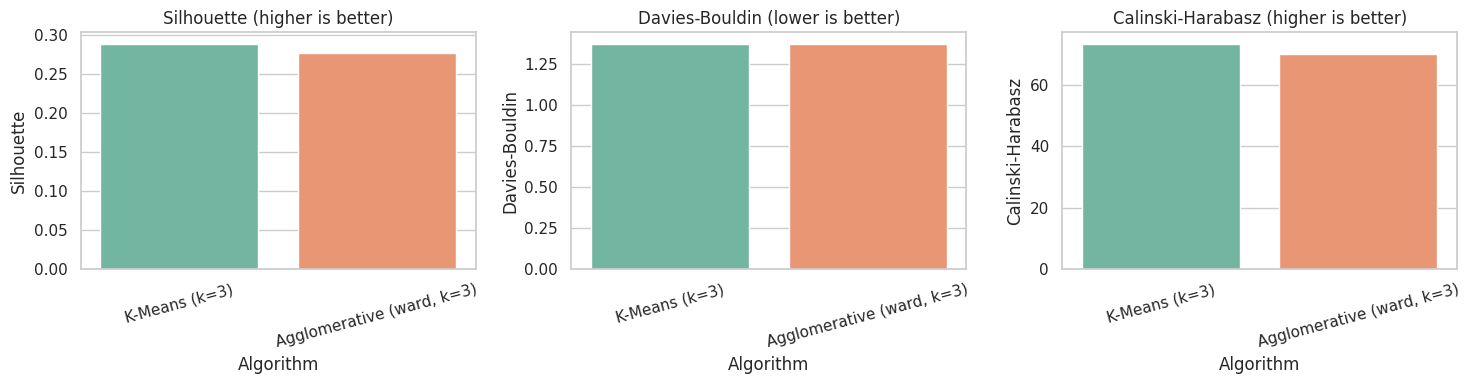

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, note in zip(axes, ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"],
                            ["higher is better", "lower is better", "higher is better"]):
    sns.barplot(data=results_df, x="Algorithm", y=metric, hue="Algorithm",
                palette="Set2", ax=ax, legend=False)
    ax.set_title(f"{metric} ({note})")
    ax.set_xlabel("Algorithm"); ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("../figures/clu_metric_comparison.png", bbox_inches="tight")
plt.show()

## 8. PCA visualisation (2 principal components) — every algorithm

Variance explained: PC1 = 36.8%, PC2 = 19.5%, total = 56.2%


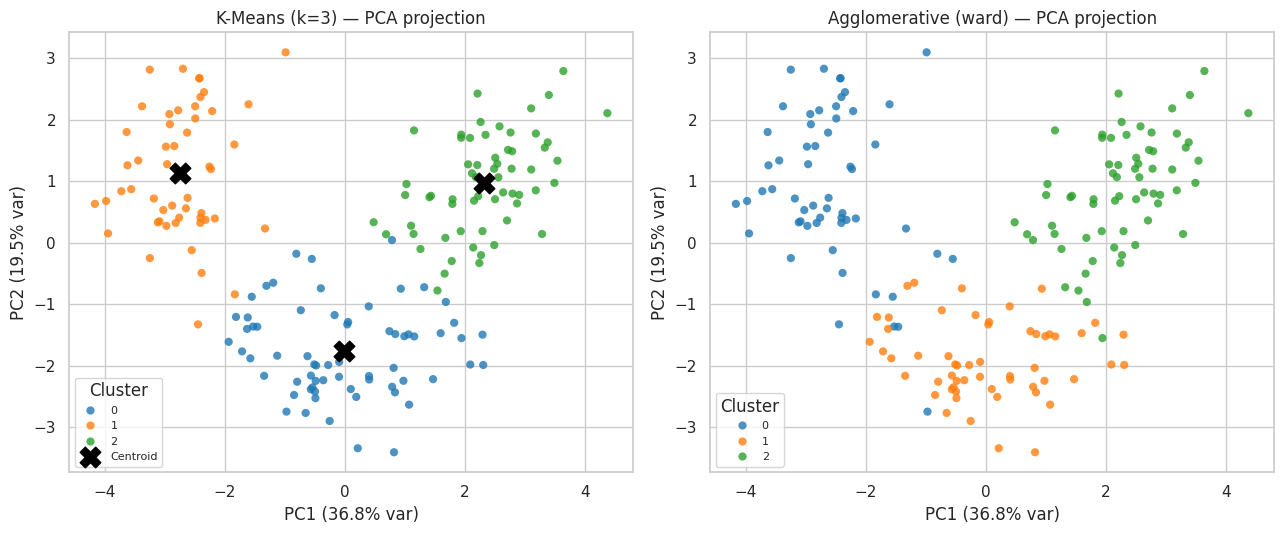

In [21]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_
print(f"Variance explained: PC1 = {evr[0]:.1%}, PC2 = {evr[1]:.1%}, total = {evr.sum():.1%}")

def plot_2d(emb, label_sets, titles, xlab, ylab, fname, centroids=None):
    fig, axes = plt.subplots(1, len(label_sets), figsize=(6.5 * len(label_sets), 5.5))
    axes = np.atleast_1d(axes)
    for i, (ax, labels, title) in enumerate(zip(axes, label_sets, titles)):
        sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=labels, palette=PALETTE,
                        s=35, alpha=0.8, ax=ax, edgecolor="none")
        if centroids is not None and centroids[i] is not None:
            ax.scatter(centroids[i][:, 0], centroids[i][:, 1], marker="X", s=220,
                       c="black", label="Centroid")
        ax.set_title(title); ax.set_xlabel(xlab); ax.set_ylabel(ylab)
        ax.legend(title="Cluster", loc="best", fontsize=8)
    plt.tight_layout()
    plt.savefig(f"../figures/{fname}", bbox_inches="tight")
    plt.show()

plot_2d(X_pca, [kmeans_labels, agglo_labels],
        [f"K-Means (k={best_k}) — PCA projection", f"Agglomerative ({best_link}) — PCA projection"],
        f"PC1 ({evr[0]:.1%} var)", f"PC2 ({evr[1]:.1%} var)", "clu_pca_clusters.png",
        centroids=[pca.transform(kmeans.cluster_centers_), None])

## 9. t-SNE visualisation (both algorithms)

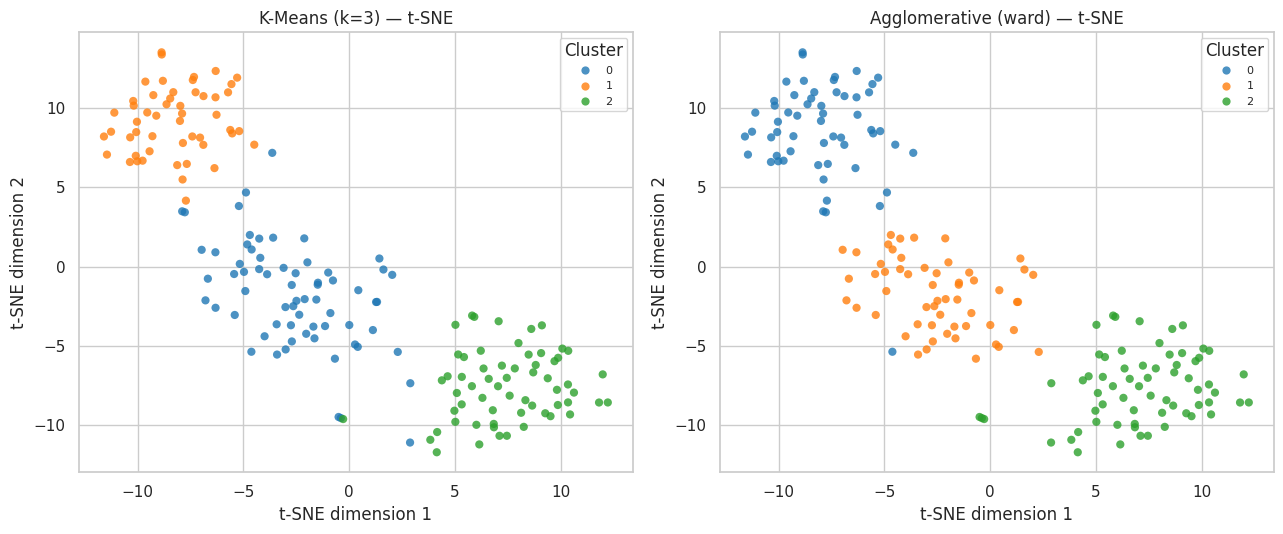

In [22]:
perplexity = min(30, max(5, (len(X_scaled) - 1) // 3))
tsne = TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_scaled)
plot_2d(X_tsne, [kmeans_labels, agglo_labels],
        [f"K-Means (k={best_k}) — t-SNE", f"Agglomerative ({best_link}) — t-SNE"],
        "t-SNE dimension 1", "t-SNE dimension 2", "clu_tsne_clusters.png")

## 10. Post-hoc validation with ground-truth labels


,Algorithm,ARI,NMI
0,K-Means (k=3),0.9149,0.8926
1,"Agglomerative (ward, k=3)",0.7605,0.7643


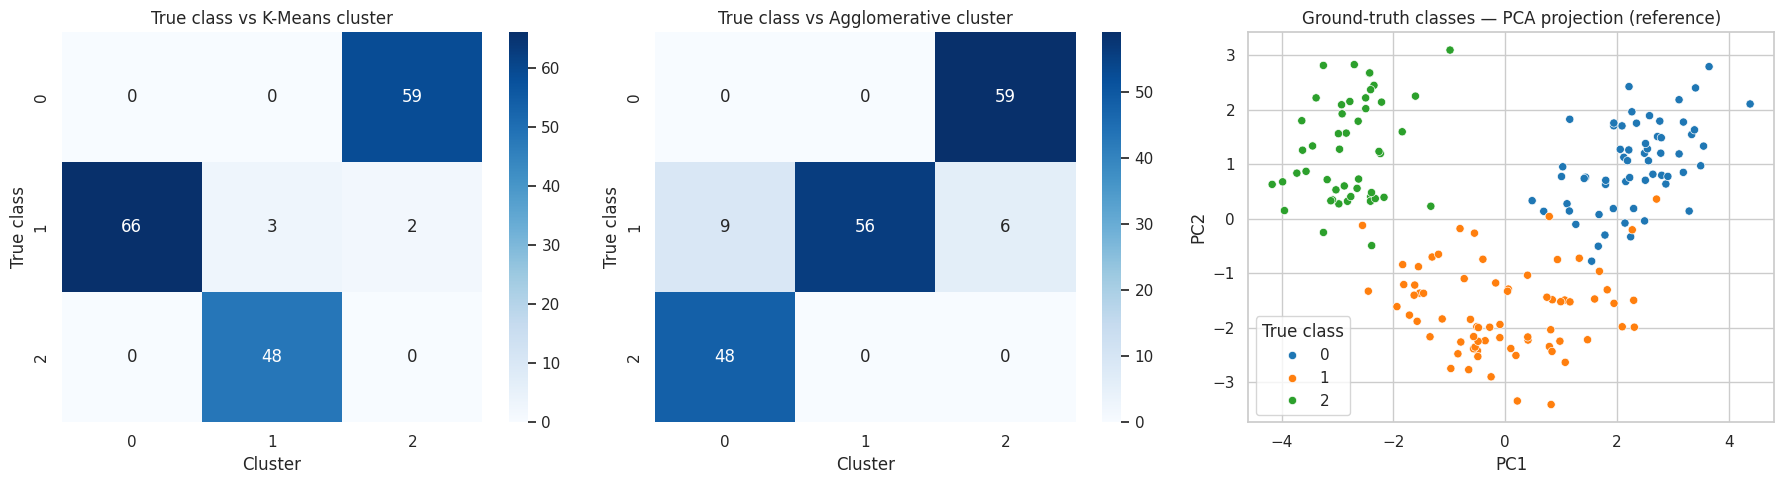

In [23]:
if y_true is not None:
    ext = pd.DataFrame([
        {"Algorithm": f"K-Means (k={best_k})",
         "ARI": adjusted_rand_score(y_true, kmeans_labels),
         "NMI": normalized_mutual_info_score(y_true, kmeans_labels)},
        {"Algorithm": f"Agglomerative ({best_link}, k={best_k})",
         "ARI": adjusted_rand_score(y_true, agglo_labels),
         "NMI": normalized_mutual_info_score(y_true, agglo_labels)},
    ])
    display(ext.round(4))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, lab, t in zip(axes[:2], [kmeans_labels, agglo_labels], ["K-Means", "Agglomerative"]):
        ct = pd.crosstab(y_true.values, lab)
        sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax)
        ax.set_title(f"True class vs {t} cluster"); ax.set_xlabel("Cluster"); ax.set_ylabel("True class")
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_true.values, palette=PALETTE, s=35, ax=axes[2])
    axes[2].set_title("Ground-truth classes — PCA projection (reference)")
    axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2"); axes[2].legend(title="True class")
    plt.tight_layout()
    plt.savefig("../figures/clu_label_validation.png", bbox_inches="tight")
    plt.show()
else:
    print("No ground-truth labels — skipping external validation.")

## 11. Cluster profiling — what distinguishes each cluster?

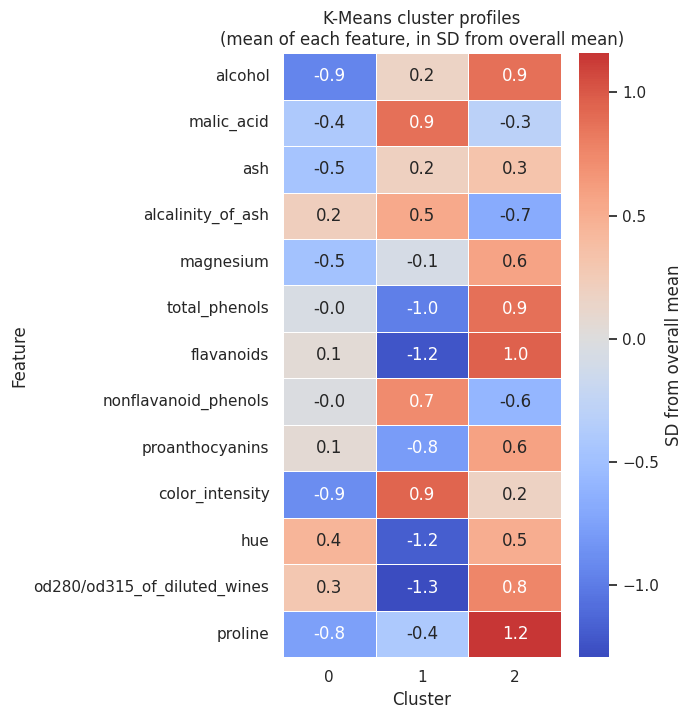

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,
0,12.247,1.898,2.248,20.202,93.118,2.262,2.076,0.359,1.620,3.030,1.056,2.817,510.180
1,13.134,3.305,2.418,21.241,98.667,1.687,0.821,0.452,1.146,7.182,0.693,1.697,619.059
2,13.701,1.997,2.450,17.260,107.455,2.833,2.967,0.289,1.919,5.445,1.068,3.151,1107.651


In [25]:
plt.figure(figsize=(2 + best_k * 1.6, 0.45 * len(num_cols) + 1.5))
sns.heatmap(z.T, cmap="coolwarm", center=0, annot=True, fmt=".1f",
            linewidths=0.5, cbar_kws={"label": "SD from overall mean"})
plt.title("K-Means cluster profiles\n(mean of each feature, in SD from overall mean)")
plt.xlabel("Cluster"); plt.ylabel("Feature")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("../figures/clu_cluster_profiles.png", bbox_inches="tight", dpi=150)
plt.show()
cluster_means.round(3)